# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:


# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')


In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción

In [10]:
# cantidad de nulos para users
print("Nulos en users (cantidad):")
print(users.isna().sum())
print("\nNulos en users (proporción):")
print(users.isna().mean())

Nulos en users (cantidad):
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Nulos en users (proporción):
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print("Nulos en usage (cantidad):")
print(usage.isna().sum())
print("\nNulos en usage (proporción):")
print(usage.isna().mean())

Nulos en usage (cantidad):
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Nulos en usage (proporción):
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.
   
**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?
**Valores nulos — Diagnóstico:**
- `users.city` (469 nulos, 11.73%): Proporción moderada (5%–30%); se investigará junto con posibles sentinels y se mantendrá como nulo (`pd.NA`) para no imputar ciudades ficticias.
- `users.churn_date` (3,534 nulos, 88.35%): Supera el 80%, pero representa clientes aún activos (sin baja); se mantiene como nulo (o se ignora para imputación).
- `usage.date` (50 nulos, 0.13%): Proporción menor al 5%; se mantendrá como nulo (`NaT`) para no eliminar registros válidos de consumo.
- `usage.duration` (22,076 nulos, 55.19%) y `usage.length` (17,896 nulos, 44.74%): Probables nulos estructurales (MAR) según el tipo de evento (`call` vs. `text`); se confirmará contra la columna `type` y, de validarse, se dejarán como nulos sin imputar.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` contiene 4,000 identificadores consecutivos entre 10000 y 13999; es una llave identificadora y no una métrica de negocio.
- La columna `age` presenta un valor sentinel inválido (`-999`), que reduce artificialmente la media a 33.74 años y eleva la desviación estándar a 123.23, mientras que los cuartiles (32, 47, 63) y el máximo (79) reflejan edades realistas.

In [13]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` son identificadores completos (40,000 registros sin nulos); `id` va de 1 a 40,000 y `user_id` coincide con el rango de usuarios (10,000 a 13,999).
- Las columnas `duration` (17,924 no nulos) y `length` (22,104 no nulos) no muestran valores negativos ni sentinels evidentes. `duration` presenta sesgo a la derecha (media 5.20 vs. mediana 3.50, máximo 120.00) y `length` muestra una dispersión elevada impulsada por extremos altos (mediana 50, Q3 64, pero máximo 1,490 y std 56.61), lo que anticipa outliers a revisar en etapas posteriores.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(f"\n--- {col} ---")
    print(users[col].value_counts(dropna=False))


--- city ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

--- plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` incluye 6 ciudades válidas de Colombia y México (Bogotá, CDMX, Medellín, GDL, Cali, MTY), pero además de los 469 valores nulos (`NaN`, 11.73%) presenta el valor sentinel `"?"` en 96 registros (2.40%), el cual debe convertirse a `pd.NA`.
- La columna `plan` está completa y consistente, con solo dos categorías válidas: `Basico` (2,595 usuarios, 64.88%) y `Premium` (1,405 usuarios, 35.13%).

In [15]:


#explorar columna categórica de usage
usage['type'].value_counts(dropna=False)




text    22092
call    17908
Name: type, dtype: int64

- La columna `type` está completa y consistente (40,000 registros sin nulos ni sentinels), distribuida en `text` (22,092 eventos, 55.23%) y `call` (17,908 eventos, 44.77%).

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  

- **¿En qué columnas encontraste valores inválidos o sentinels?**
  - **`users.age`:** Se detectó el valor *sentinel* `-999` como mínimo, el cual distorsiona la media (`33.74` años) y dispara la desviación estándar (`123.23`), mientras los cuartiles (`32`, `47`, `63`) y el máximo (`79`) son coherentes.
  - **`users.city`:** Se encontró el *sentinel* `"?"` en **96 registros (2.40%)**, adicional a los `469` valores nulos (`NaN`, 11.73%) ya existentes.
  - **`users.plan` y `usage.type`:** Sin valores inválidos ni *sentinels* (categorías limpias y completas).
  - **`usage.duration` y `usage.length`:** Sin valores negativos ni *sentinels* evidentes (aunque presentan máximos altos de `120` min y `1,490` caracteres que se evaluarán como *outliers* en el Paso 5).
    

- **¿Qué acción tomarías?**
  - En **`users.age`**: Reemplazar `-999` por la **mediana** calculada únicamente sobre las edades válidas (excluyendo `-999`) para no sesgar las estadísticas ni perder los registros.
  - En **`users.city`**: Reemplazar `"?"` por valores nulos (`pd.NA`) para evitar crear una categoría ficticia y mantener la trazabilidad de datos faltantes.
  - En **`users.plan`, `usage.type`, `usage.duration` y `usage.length`**: No aplicar limpieza de *sentinels* en esta etapa; conservar los datos intactos para el análisis posterior de nulos MAR y *outliers*.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [17]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')


In [18]:

# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()



2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, los registros se distribuyen de forma equilibrada entre 2022 (1,314), 2023 (1,316) y 2024 (1,330), sin valores nulos. Sin embargo, se detectaron 40 registros con año 2026 (1.00% del total), lo cual corresponde a fechas futuras imposibles dado que el corte de datos es 2024.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()


2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, todos los registros válidos (39,950 eventos, 99.88%) corresponden al año 2024, y se mantienen únicamente los 50 valores nulos originales (0.13%). No aparecen años futuros ni fuera de rango.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  

- **¿Aparecen años imposibles?** (años muy viejos o sin transcurrir al momento de guardar los datos)
- 
  - En **`users.reg_date`**: Sí, aparecen **40 registros con año 2026** (1.00% del total), lo cual es imposible dado que el corte de los datos es 2024. El resto se distribuye normalmente entre 2022 (1,314), 2023 (1,316) y 2024 (1,330).
  - En **`usage.date`**: No aparecen años imposibles; los 39,950 registros con fecha válida pertenecen a 2024 y los 50 faltantes (0.13%) corresponden a los nulos originales.

- **¿Qué harías con ellas?**
  - En **`users.reg_date`**: Marcar las 40 fechas posteriores a 2024 como valores nulos (`pd.NA` / `NaT`) para no distorsionar análisis temporales ni perder el perfil del usuario.
  - En **`usage.date`**: Conservar los 50 nulos como `NaT` sin eliminar las filas, ya que representan menos del 1% y preservan el volumen real de consumo por usuario.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango

In [20]:
# Reemplazar -999 por la mediana de age (excluyendo el sentinel del cálculo)
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [22]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión..

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()


type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()


type
call    0.99933
text    0.00000
Name: length, dtype: float64

**Diagnóstico de nulos en `duration` y `length`:**
Se confirma que los valores faltantes son **MAR (Missing At Random / estructurales)** y dependen directamente de la columna `type`:
- `duration` presenta **0.00%** de nulos en `call` y **99.93%** en `text` (la duración solo aplica a llamadas).
- `length` presenta **0.00%** de nulos en `text` y **99.93%** en `call` (la longitud de caracteres solo aplica a mensajes).

**Decisión:** Se mantienen como valores nulos (`NaN`) sin imputar ni eliminar filas, ya que reflejan la naturaleza de cada servicio y rellenarlos (por ejemplo, con `0` o la mediana) sesgaría las métricas promedio de llamadas y mensajes.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`

In [25]:

# Crear columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)  # total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int)  # total de llamadas


In [26]:
# Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id")[["is_text", "is_call", "duration"]]
    .sum()
    .reset_index()
)

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Renombrar columnas y guardar el cambio
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})


In [28]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# observar resultado
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [29]:
# Resumen estadístico del Paso 4.2
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[columnas_numericas].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [30]:

# Distribución porcentual del tipo de plan
(user_profile['plan'].value_counts(normalize=True) * 100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas.

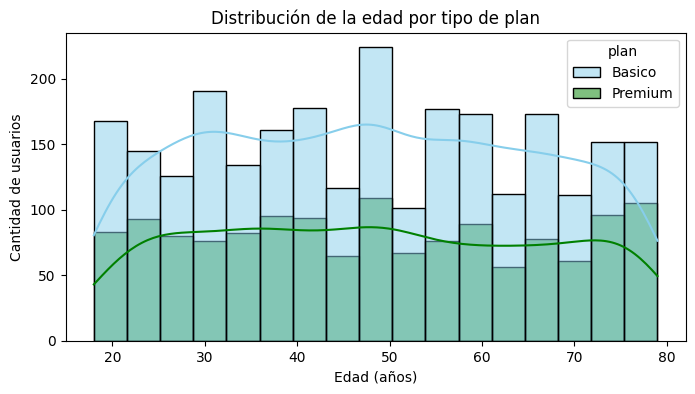

In [31]:


# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de la edad por tipo de plan')
plt.xlabel('Edad (años)')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights:
- **Distribución uniforme (simétrica/plana):** Las edades de los clientes se reparten de manera muy pareja entre los 18 y 79 años, sin sesgo hacia jóvenes ni adultos mayores. El pico alrededor de los 47–50 años responde a la imputación por mediana realizada para corregir el sentinel `-999`.
- **Sin diferenciación por plan:** Tanto `Basico` como `Premium` mantienen exactamente el mismo perfil etario (la mayor altura de `Basico` solo refleja su mayor proporción en la base total), por lo que la edad por sí sola no determina la elección del plan.

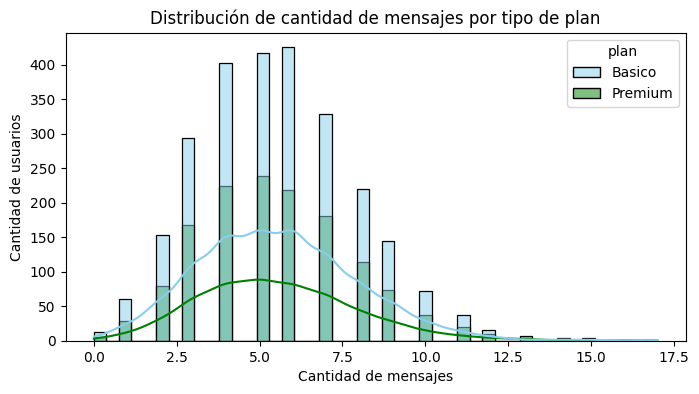

In [32]:
# Histograma para visualizar cant_mensajes
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de cantidad de mensajes por tipo de plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights:
- **Distribución ligeramente sesgada a la derecha:** La mayoría de los usuarios envía entre 3 y 8 mensajes, con un pico alrededor de 5 mensajes y una cola que se extiende hasta 17 mensajes.
- **Sin diferenciación entre planes:** `Basico` y `Premium` muestran exactamente el mismo patrón de envío de mensajes (la mayor altura de `Basico` solo responde a su mayor proporción de usuarios).

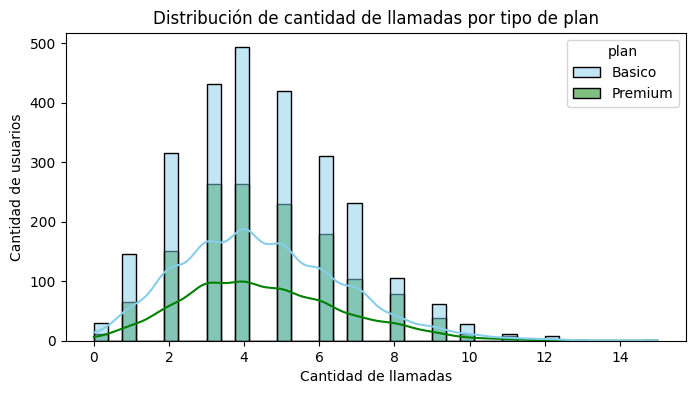

In [33]:

# Histograma para visualizar cant_llamadas
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de cantidad de llamadas por tipo de plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()



💡Insights:
- **Distribución ligeramente sesgada a la derecha:** La mayoría de los usuarios realiza entre 2 y 7 llamadas, con un pico concentrado en 3–4 llamadas y una cola que disminuye hasta ~12–15 llamadas.
- **Sin diferenciación entre planes:** `Basico` y `Premium` presentan el mismo patrón de consumo de llamadas (la diferencia de altura solo refleja el mayor volumen total de usuarios en el plan Básico).
  

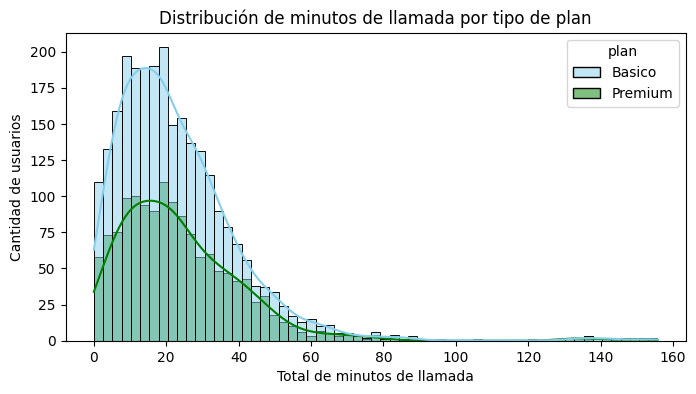

In [34]:
# Histograma para visualizar cant_minutos_llamada
plt.figure(figsize=(8, 4))
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de minutos de llamada por tipo de plan')
plt.xlabel('Total de minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights:
- **Distribución fuertemente sesgada a la derecha:** La mayoría de los usuarios acumula entre 0 y 40 minutos de llamada, con un pico alrededor de los 10–20 minutos. Existe una cola larga que se extiende por encima de los 80 minutos hasta ~155 minutos, anticipando posibles *outliers* de alto consumo.
- **Sin diferenciación entre planes:** Tanto `Basico` como `Premium` presentan la misma distribución y el mismo consumo típico de minutos (la mayor altura de `Basico` solo refleja su mayor proporción de usuarios).

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna..

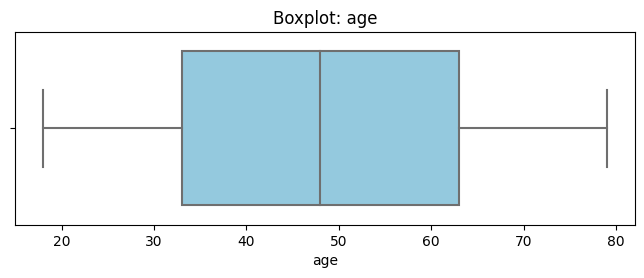

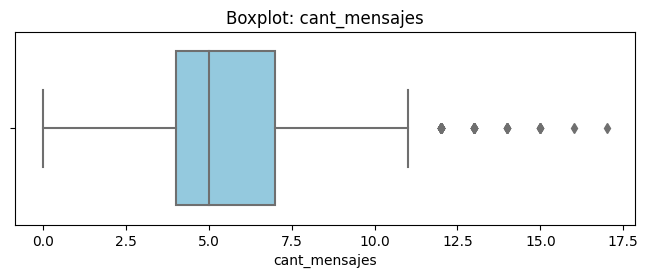

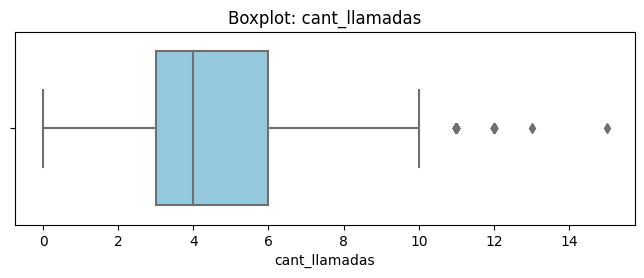

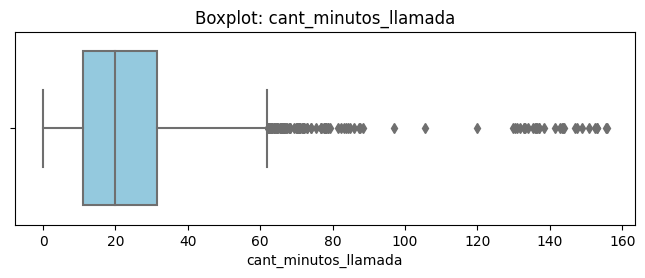

In [35]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:
- **Age:** No presenta *outliers*; la distribución es limpia y simétrica entre ~18 y ~79 años, con mediana alrededor de 48 años.
- **cant_mensajes:** Sí presenta *outliers* únicamente en el extremo superior (a partir de 12 hasta ~17 mensajes), con la caja concentrada entre 4 y 7 mensajes.
- **cant_llamadas:** Sí presenta *outliers* únicamente en el extremo superior (entre 11 y 15 llamadas), con la caja concentrada entre 3 y 6 llamadas.
- **cant_minutos_llamada:** Sí presenta abundantes *outliers* únicamente en el extremo superior (por encima de ~62 minutos hasta ~155 minutos), incluyendo un grupo notablemente separado entre 130 y 155 minutos.

In [36]:

# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    
    n_outliers = (user_profile[col] > limite_superior).sum()
    pct_outliers = (n_outliers / len(user_profile)) * 100
    
    print(f"{col}:")
    print(f"  Q1 = {Q1:.2f} | Q3 = {Q3:.2f} | IQR = {IQR:.2f}")
    print(f"  Límite superior = {limite_superior:.2f}")
    print(f"  Outliers = {n_outliers} usuarios ({pct_outliers:.2f}%)\n")



cant_mensajes:
  Q1 = 4.00 | Q3 = 7.00 | IQR = 3.00
  Límite superior = 11.50
  Outliers = 46 usuarios (1.15%)

cant_llamadas:
  Q1 = 3.00 | Q3 = 6.00 | IQR = 3.00
  Límite superior = 10.50
  Outliers = 30 usuarios (0.75%)

cant_minutos_llamada:
  Q1 = 11.12 | Q3 = 31.41 | IQR = 20.30
  Límite superior = 61.86
  Outliers = 109 usuarios (2.73%)



In [37]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()



,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000



💡Insights:
- **cant_mensajes:** **Mantener *outliers*.** Aunque 46 usuarios (1.15%) superan el límite superior de 11.50, el máximo es de 17 mensajes, un valor completamente realista de consumo y no un error de registro. Además, no distorsionan la tendencia central (media de 5.52 vs. mediana de 5.00).
- **cant_llamadas:** **Mantener *outliers*.** Solo 30 usuarios (0.75%) superan el límite superior de 10.50, llegando a un máximo de 15 llamadas. Representan clientes reales con mayor frecuencia de uso y mantienen la media (4.48) muy cercana a la mediana (4.00).
- **cant_minutos_llamada:** **Mantener *outliers*.** Los 109 usuarios (2.73%) por encima del límite superior de 61.86 min alcanzan un máximo de 155.69 min (~2.6 horas), lo cual es totalmente plausible para el consumo anual. Corresponden a clientes de alto valor (*heavy users*) que es fundamental conservar para la segmentación y estrategias de conversión a Premium.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos.

In [38]:
# Rellenar con 0 el único usuario sin actividad registrada para evitar que caiga en 'Alto uso'
cols_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

# Definir condiciones y etiquetas en orden jerárquico
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
etiquetas = ['Bajo uso', 'Uso medio']

# Crear columna grupo_uso
user_profile['grupo_uso'] = np.select(condiciones, etiquetas, default='Alto uso')

# Verificar cambios y distribución de segmentos
print(user_profile['grupo_uso'].value_counts())



Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64


In [39]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos.

In [40]:
# Crear columna grupo_edad
# Definir condiciones y etiquetas en orden jerárquico
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]
etiquetas_edad = ['Joven', 'Adulto']

# Crear columna grupo_edad
user_profile['grupo_edad'] = np.select(condiciones_edad, etiquetas_edad, default='Adulto Mayor')

# Verificar cambios y distribución de segmentos
print(user_profile['grupo_edad'].value_counts())


Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


In [41]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico..

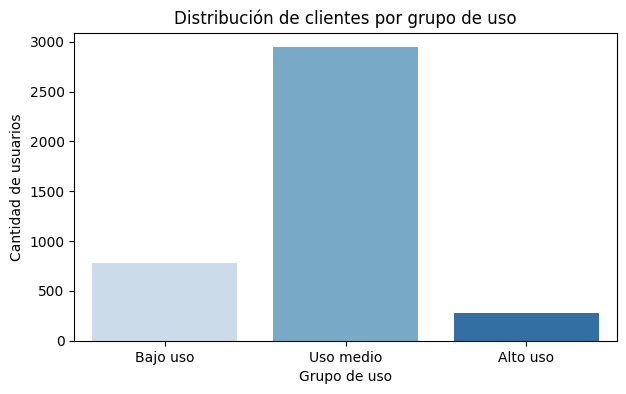

In [42]:
# Visualización de los segmentos por uso
plt.figure(figsize=(7, 4))
sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso'],
    palette='Blues'
)
plt.title('Distribución de clientes por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

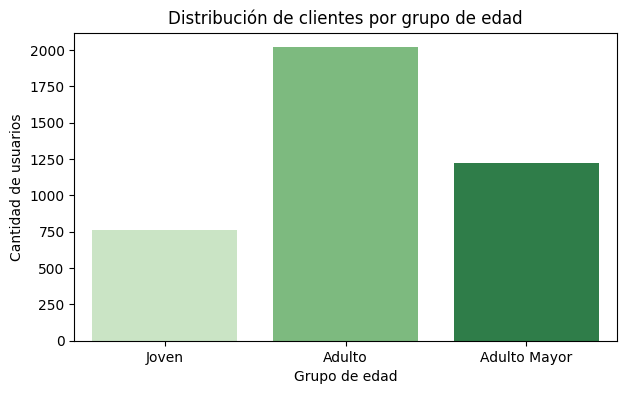

In [43]:

# Visualización de los segmentos por edad
plt.figure(figsize=(7, 4))
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor'],
    palette='Greens'
)
plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


--- 
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**


## Análisis ejecutivo

### ⚠️ Problemas detectados en los datos
- **Edades inválidas (`age`):** Se identificaron valores centinela `-999` en **55 filas (1.38%)** de los usuarios, los cuales fueron imputados con la mediana (**48 años**) para preservar la distribución (rango final: 18 a 79 años) sin sesgar los estadísticos.
- **Ciudades sin registro (`city`):** Tras estandarizar el carácter `?` como valor faltante (`pd.NA`), se consolidaron **565 registros faltantes (14.13%)** en la columna.
- **Fechas futuras (`reg_date`):** Se detectaron **40 registros (1.00%)** con fechas posteriores a 2024, los cuales fueron convertidos a `NaT` para evitar distorsiones temporales.
- **Nulos estructurales (MAR) en `usage`:** Los valores faltantes en `duration` (en mensajes) y `length` (en llamadas) responden a la naturaleza de cada evento (*Missing At Random*), por lo que se conservaron como `NaN` para no sesgar los promedios.
- **Usuario sin actividad:** Se detectó **1 usuario (0.025%)** sin registros en la tabla `usage`, cuyos valores de consumo se imputaron en `0` antes de segmentar para evitar clasificarlo erróneamente como *Alto uso*.

### 🔍 Segmentos por Edad
- **Adultos (30–59 años):** Representan el **50.45% (2,018 usuarios)** y constituyen el núcleo principal de la base de clientes.
- **Adultos Mayores (60+ años):** Concentran el **30.55% (1,222 usuarios)**, un bloque relevante que exige oferta clara y soporte accesible.
- **Jóvenes (< 30 años):** Corresponden al **19.00% (760 usuarios)**, el segmento más pequeño.
- **Comportamiento frente al plan:** La edad sigue una distribución uniforme entre 18 y 79 años y **no muestra diferencias entre `Basico` y `Premium`**; la edad por sí sola no define el tipo de plan contratado.

### 📊 Segmentos por Nivel de Uso
- **Uso medio:** Concentra la gran mayoría de la base con **73.58% (2,943 usuarios)**, con consumos típicos centrados alrededor de 5 mensajes, 4 llamadas y ~20 minutos acumulados.
- **Bajo uso:** Agrupa al **19.48% (779 usuarios)** con menos de 5 llamadas y menos de 5 mensajes, representando un segmento con riesgo latente de baja actividad o abandono (*churn*).
- **Alto uso:** Conformado por **6.95% (278 usuarios)**, es el segmento más valioso para ConnectaTel junto con los *heavy users* detectados en el análisis de *outliers*: **46 usuarios (1.15%)** superan 11.5 mensajes (hasta 17), **30 usuarios (0.75%)** superan 10.5 llamadas (hasta 15) y **109 usuarios (2.73%)** superan 61.86 minutos (hasta 155.69 min). Estos extremos son consumos reales y se mantuvieron por su alto potencial comercial.

➡️ **Esto sugiere que** actualmente los planes `Basico` y `Premium` **no están diferenciados por el comportamiento real de consumo**: ambos presentan distribuciones prácticamente idénticas en mensajes, llamadas y minutos. ConnectaTel tiene usuarios de alto consumo pagando un plan básico (pérdida de ingresos potenciales) y clientes de bajo uso que podrían no percibir suficiente valor en su tarifa actual.

### 💡 Recomendaciones
- **Campaña de *upselling* dirigida a *Alto uso* y *outliers* en plan Básico:** Identificar a los usuarios del segmento **Alto uso (6.95%)** y a los **109 *heavy users* de minutos** que hoy están en `Basico` para ofrecerles una migración incentivada a `Premium` (por ejemplo, minutos ilimitados o tarifas preferenciales por volumen).
- **Rediseñar la propuesta de valor del plan `Premium`:** Incorporar beneficios claramente alineados al uso intensivo de voz (paquetes de minutos extendidos o bonos por consumo) para justificar la brecha frente a `Basico` y fidelizar al segmento más rentable.
- **Plan de entrada o esquema flexible para `Bajo uso` (19.48%):** Crear un plan ligero o prepago/por consumo dirigido a los 779 usuarios de menor actividad, junto con campañas de reactivación para reducir el riesgo de *churn*.
- **Personalización por perfil etario:** Aunque el consumo no varía por edad, la comunicación comercial sí debe adaptarse: canales digitales y beneficios ágiles para **Jóvenes (19%)**, planes estables y familiares para **Adultos (50.45%)** y atención simplificada enfocada en voz para **Adultos Mayores (30.55%)**

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`